# GNN for Drug Discovery

**Goal:** predict aqueous solubility from molecular graphs using a lightweight Graph Convolutional Network (GCN).

**Dataset:** Delaney/ESOL — 1,128 compounds with SMILES and measured log solubility.

**Why this setup?** It is intentionally small enough for CPU training and keeps the complete workflow in one notebook. RDKit converts chemical structures into graphs; PyTorch Geometric performs graph learning; Flask later exposes the trained model through a browser.

## 1. Imports and configuration

The code uses a fixed random seed and a small model so the experiment remains practical on a CPU.

In [1]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool

from rdkit import Chem
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
MODEL_DIR = ROOT / 'models'
DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

DATA_URL = 'https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv'
DATA_PATH = DATA_DIR / 'delaney-processed.csv'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

c:\Users\user\Desktop\GNN-for-Drug-Discovery\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device: cpu


## 2. Download the open dataset

The CSV is downloaded only when it is not already present. It is deliberately not committed to Git so the repository remains small.

In [2]:
if not DATA_PATH.exists():
    response = requests.get(DATA_URL, timeout=60)
    response.raise_for_status()
    DATA_PATH.write_bytes(response.content)
    print('Downloaded:', DATA_PATH)
else:
    print('Using cached file:', DATA_PATH)

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df[['Compound ID', 'smiles', 'measured log solubility in mols per litre']].head()

Downloaded: c:\Users\user\Desktop\GNN-for-Drug-Discovery\data\delaney-processed.csv
Shape: (1128, 10)


,Compound ID,smiles,measured log solubility in mols per litre
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,citral,CC(C)=CCCC(C)=CC(=O),-2.06
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,Thiophene,c1ccsc1,-1.33


## 3. Inspect the target

The target is measured log solubility in mol/L. This is a regression problem.

count    1128.000000
mean       -3.050102
std         2.096441
min       -11.600000
25%        -4.317500
50%        -2.860000
75%        -1.600000
max         1.580000
Name: measured log solubility in mols per litre, dtype: float64


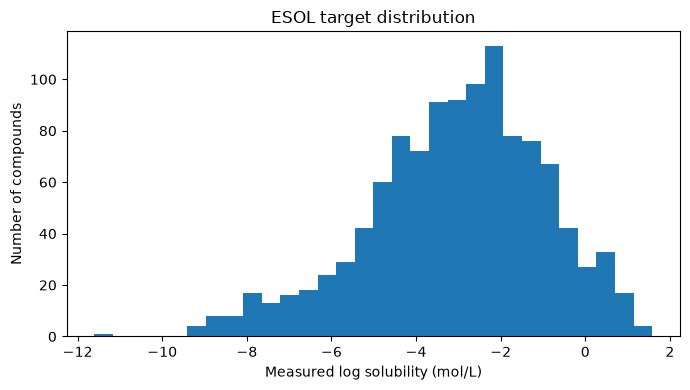

In [3]:
TARGET = 'measured log solubility in mols per litre'
print(df[TARGET].describe())

plt.figure(figsize=(7, 4))
plt.hist(df[TARGET], bins=30)
plt.xlabel('Measured log solubility (mol/L)')
plt.ylabel('Number of compounds')
plt.title('ESOL target distribution')
plt.tight_layout()
plt.show()

## 4. Convert a molecule into a graph

Each atom becomes a node. Chemical bonds become bidirectional edges. The node vector contains simple, interpretable atom-level features:

- atomic number
- degree
- formal charge
- total hydrogen count
- aromatic flag
- ring flag
- atomic mass
- hybridization one-hot features

This avoids large molecular fingerprints and keeps the model lightweight.

In [4]:
HYBRIDIZATIONS = [
    Chem.HybridizationType.SP,
    Chem.HybridizationType.SP2,
    Chem.HybridizationType.SP3,
    Chem.HybridizationType.SP3D,
    Chem.HybridizationType.SP3D2,
]

def atom_features(atom):
    hybrid = [float(atom.GetHybridization() == h) for h in HYBRIDIZATIONS]
    return [
        atom.GetAtomicNum() / 100.0,
        atom.GetDegree() / 5.0,
        atom.GetFormalCharge() / 3.0,
        atom.GetTotalNumHs() / 4.0,
        float(atom.GetIsAromatic()),
        float(atom.IsInRing()),
        atom.GetMass() / 250.0,
        *hybrid,
    ]

def smiles_to_graph(smiles, target=None):
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None or molecule.GetNumAtoms() == 0:
        return None

    x = torch.tensor([atom_features(atom) for atom in molecule.GetAtoms()], dtype=torch.float)

    edges = []
    for bond in molecule.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()
        edges.extend([(i, j), (j, i)])

    if edges:
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    data = Data(x=x, edge_index=edge_index)
    if target is not None:
        data.y = torch.tensor([float(target)], dtype=torch.float)
    return data

example = smiles_to_graph('CCO', -0.3)
print(example)
print('Node feature dimension:', example.x.shape[1])

Data(x=[3, 12], edge_index=[2, 4], y=[1])
Node feature dimension: 12


## 5. Build the graph dataset

Invalid SMILES entries, if any, are skipped rather than stopping the entire experiment.

In [5]:
graphs = []
invalid = 0

for _, row in df.iterrows():
    graph = smiles_to_graph(row['smiles'], row[TARGET])
    if graph is None:
        invalid += 1
        continue
    graph.smiles = row['smiles']
    graph.compound_id = str(row['Compound ID'])
    graphs.append(graph)

print('Valid graphs:', len(graphs))
print('Skipped:', invalid)
print('Example graph:', graphs[0])

Valid graphs: 1128
Skipped: 0
Example graph: Data(x=[32, 12], edge_index=[2, 68], y=[1], smiles='OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O ', compound_id='Amigdalin')


## 6. Train/validation/test split

A deterministic 80/10/10 split is used to keep the example easy to reproduce. For a research setting, a scaffold split should also be considered because molecules sharing structural scaffolds can make random splits optimistic.

In [6]:
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(graphs), generator=generator).tolist()

n = len(indices)
train_end = int(0.80 * n)
val_end = int(0.90 * n)

train_graphs = [graphs[i] for i in indices[:train_end]]
val_graphs = [graphs[i] for i in indices[train_end:val_end]]
test_graphs = [graphs[i] for i in indices[val_end:]]

print(len(train_graphs), len(val_graphs), len(test_graphs))

train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
val_loader = DataLoader(val_graphs, batch_size=64, shuffle=False)
test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)

902 113 113


## 7. Define the GCN

The network applies two graph convolution layers. Each node receives information from neighboring atoms. Global mean pooling then converts a variable-size molecular graph into a fixed-size vector for regression.

In [7]:
class MoleculeGNN(nn.Module):
    def __init__(self, in_channels, hidden_channels=64):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.regressor = nn.Sequential(
            nn.Linear(hidden_channels, 32),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(32, 1),
        )

    def forward(self, x, edge_index, batch):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = global_mean_pool(x, batch)
        return self.regressor(x).view(-1)

model = MoleculeGNN(graphs[0].num_node_features).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()
print(model)

MoleculeGNN(
  (conv1): GCNConv(12, 64)
  (conv2): GCNConv(64, 64)
  (regressor): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 8. Train on CPU/GPU

The default is only 30 epochs. On a CPU this is intentionally modest; the objective is a reproducible portfolio demonstration rather than a large-scale benchmark.

In [8]:
def run_epoch(loader, training=True):
    model.train(training)
    total_loss = 0.0
    count = 0

    for batch in loader:
        batch = batch.to(DEVICE)
        if training:
            optimizer.zero_grad()

        prediction = model(batch.x, batch.edge_index, batch.batch)
        loss = loss_fn(prediction, batch.y.view(-1))

        if training:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * batch.num_graphs
        count += batch.num_graphs

    return total_loss / max(count, 1)

history = {'train': [], 'val': []}
EPOCHS = 30

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)
    history['train'].append(train_loss)
    history['val'].append(val_loss)

    if epoch == 1 or epoch % 5 == 0:
        print(f'Epoch {epoch:02d} | train MSE {train_loss:.4f} | val MSE {val_loss:.4f}')

Epoch 01 | train MSE 10.3819 | val MSE 7.3642
Epoch 05 | train MSE 3.8620 | val MSE 4.3887
Epoch 10 | train MSE 3.7740 | val MSE 4.1047
Epoch 15 | train MSE 3.6345 | val MSE 3.8495
Epoch 20 | train MSE 3.3641 | val MSE 3.5928
Epoch 25 | train MSE 3.1713 | val MSE 3.3993
Epoch 30 | train MSE 2.9969 | val MSE 3.2356


## 9. Evaluate the model

MAE is easy to interpret as the average absolute error in log-solubility units. RMSE gives more weight to larger errors.

In [9]:
def predict(loader):
    model.eval()
    predictions, actuals = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            pred = model(batch.x, batch.edge_index, batch.batch)
            predictions.extend(pred.cpu().numpy())
            actuals.extend(batch.y.view(-1).cpu().numpy())
    return np.array(predictions), np.array(actuals)

pred, actual = predict(test_loader)
mae = mean_absolute_error(actual, pred)
rmse = np.sqrt(mean_squared_error(actual, pred))
print(f'Test MAE:  {mae:.4f}')
print(f'Test RMSE: {rmse:.4f}')

Test MAE:  1.2895
Test RMSE: 1.6846


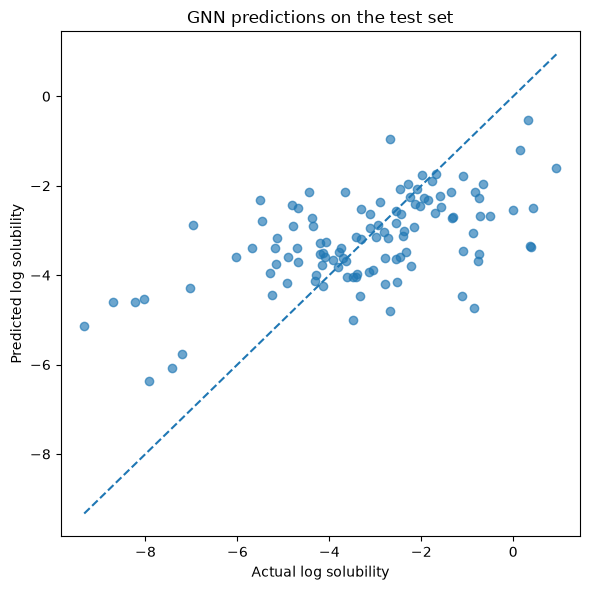

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(actual, pred, alpha=0.65)
low = min(actual.min(), pred.min())
high = max(actual.max(), pred.max())
plt.plot([low, high], [low, high], linestyle='--')
plt.xlabel('Actual log solubility')
plt.ylabel('Predicted log solubility')
plt.title('GNN predictions on the test set')
plt.tight_layout()
plt.show()

## 10. Save the model for the Flask app

Only the learned parameters and small configuration metadata are saved. The dataset itself is not copied into the model directory.

In [11]:
model_path = MODEL_DIR / 'gnn_esol.pt'
config_path = MODEL_DIR / 'model_config.json'

torch.save(model.state_dict(), model_path)

config = {
    'in_channels': int(graphs[0].num_node_features),
    'hidden_channels': 64,
    'target': TARGET,
    'seed': SEED,
    'epochs': EPOCHS,
    'test_mae': float(mae),
    'test_rmse': float(rmse),
}
config_path.write_text(json.dumps(config, indent=2))

print('Saved:', model_path)
print('Saved:', config_path)

Saved: c:\Users\user\Desktop\GNN-for-Drug-Discovery\models\gnn_esol.pt
Saved: c:\Users\user\Desktop\GNN-for-Drug-Discovery\models\model_config.json


## 11. Test the exact inference path used by Flask

This final cell confirms that a new SMILES string can be converted into a graph and passed through the trained network.

In [12]:
def predict_smiles(smiles):
    graph = smiles_to_graph(smiles)
    if graph is None:
        raise ValueError('Invalid SMILES string')
    graph = graph.to(DEVICE)
    batch = torch.zeros(graph.num_nodes, dtype=torch.long, device=DEVICE)
    model.eval()
    with torch.no_grad():
        value = model(graph.x, graph.edge_index, batch).item()
    return value

for smiles in ['CCO', 'CC(=O)O', 'c1ccccc1']:
    print(smiles, '->', round(predict_smiles(smiles), 3))

CCO -> -2.178
CC(=O)O -> -0.627
c1ccccc1 -> -2.378


## 12. Next step: launch the Flask demo

From the repository root, run:

```bash
python app.py
```

Then open `http://127.0.0.1:5000`. The app uses the same graph construction and GCN architecture defined here.